# Day 20/100 — BundleRecommender | FULL MASTER v1

**Problem:** Sellers need interpretable product bundles supported by actual transaction co-occurrence.

**Input:** `/kaggle/input/datasets/wafabila/bundlerecommender-dataset` (Instacart + UCI Online Retail II). The code discovers files by **schema**, not presumed folder spelling. CSV, XLSX, nested ZIP and uploaded folder layouts are supported.

**Research contract:** Real observed baskets; do not claim causal lift or conversion improvements. Evaluate association rules on later Instacart orders per shopper; UCI is a *separate domain experiment* with no shared product IDs. Training rules are not evaluated on the same baskets used to mine them. Association rules are descriptive, not a recommender personalized to users.

**Outputs:** `models/`, `reports/`, `assets/plots/`, `exports/`, `notebooks/` under `/kaggle/working/bundlerecommender_master_v1` and one release ZIP. No raw third-party transaction data in ZIP.

**Source:** [Instacart Market Basket Analysis](https://www.kaggle.com/competitions/instacart-market-basket-analysis/data) (downloaded from mirror as original contest page may be inaccessible); [UCI Online Retail II](https://archive.ics.uci.edu/dataset/502/online+retail+ii) (original source, CC BY 4.0). Verify mirror terms before redistributing data.

In [1]:
%pip -q install "mlxtend>=0.23,<1" "openpyxl>=3.1,<4"

Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import os, json, re, sys, time, zipfile, hashlib, warnings
from collections import Counter
from io import BytesIO
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from mlxtend.frequent_patterns import fpgrowth, apriori, association_rules
from scipy.sparse import csr_matrix

SEED=42
ROOT=Path('/kaggle/input/datasets/wafabila/bundlerecommender-dataset')
assert ROOT.exists(), f'Missing Kaggle dataset: {ROOT}. Please Add Input.'
OUT=Path('/kaggle/working/bundlerecommender_master_v1')
for d in ['models','reports','assets/plots','exports','notebooks']:(OUT/d).mkdir(parents=True, exist_ok=True)
# Bounded experiment; adjust after inspecting memory availability.
MAX_TRAIN_BASKETS=100_000
MAX_HOLDOUT_BASKETS=25_000
TOP_PRODUCTS=120
MIN_SUPPORT=0.012
MIN_CONFIDENCE=0.15
MIN_LIFT=1.05
MAX_RULES_EXPORT=300
RUN_APRIORI=True
print('Environment:',sys.version.split()[0]);print('Input:',ROOT);print('Output:',OUT)

Environment: 3.13.15
Input: /kaggle/input/datasets/wafabila/bundlerecommender-dataset
Output: /kaggle/working/bundlerecommender_master_v1


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 1. Input inventory and integrity checks
Do not assume Kaggle unpacked a ZIP. Read CSV and XLSX from both regular paths and nested ZIP members. File size and column-level validation are recorded.

In [3]:
paths=[p for p in ROOT.rglob('*') if p.is_file() and '/.cache/' not in str(p)]
rows=[{'path':str(p.relative_to(ROOT)),'size_mb':round(p.stat().st_size/2**20,2),'extension':p.suffix.lower()} for p in paths]
inventory=pd.DataFrame(rows)
assert len(inventory)>0,'No input files visible.'
display(inventory.sort_values('size_mb',ascending=False).head(60))
inventory.to_csv(OUT/'reports/input_inventory.csv',index=False)

def find_file(name):
    direct=[p for p in paths if p.name.lower()==name.lower()]
    if direct: return ('file',direct[0],None)
    for p in paths:
        if p.suffix.lower()!='.zip':continue
        try:
            with zipfile.ZipFile(p) as z:
                options=[m for m in z.namelist() if Path(m).name.lower()==name.lower()]
                if options:return ('zip',p,options[0])
        except (OSError,zipfile.BadZipFile):
            print('WARN: invalid zip',p)
    return None

def read_csv_source(name,**kwargs):
    f=find_file(name)
    if f is None:raise FileNotFoundError(f'Not found: {name}; inspect inventory')
    kind,path,member=f
    if kind=='file':return pd.read_csv(path,**kwargs)
    with zipfile.ZipFile(path) as z:
        with z.open(member) as h:return pd.read_csv(h,**kwargs)

instacart_names=['orders.csv','order_products__prior.csv','order_products__train.csv','products.csv','aisles.csv','departments.csv']
for name in instacart_names:
    resolved=find_file(name)
    assert resolved, f'Missing Instacart file: {name}'
    print('FOUND',name, 'via',resolved[0],str(resolved[1].relative_to(ROOT)))

uci_candidates=[]
for p in paths:
    if p.suffix.lower() in ('.xlsx','.xls') and ('retail' in p.name.lower()):uci_candidates.append(('file',p,None))
    if p.suffix.lower()=='.zip':
        try:
            with zipfile.ZipFile(p) as z:
                for member in z.namelist():
                    if 'online_retail' in Path(member).name.lower() and member.lower().endswith('.xlsx'):
                        uci_candidates.append(('zip',p,member))
        except (OSError,zipfile.BadZipFile):pass
print('UCI candidates:',[(k,p.name,m) for k,p,m in uci_candidates])
assert uci_candidates,'No UCI Online Retail II XLSX found (direct or within ZIP)'
(OUT/'reports/source_contract.json').write_text(json.dumps({'root':str(ROOT),'instacart_files':instacart_names,'uci_available':True,'train_protocol':'train earlier prior orders; hold out latest prior per user; no train baskets in evaluation','note':'Mirror files are not license evidence. Check original dataset terms.'},indent=2),encoding='utf-8')

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,path,size_mb,extension
3,instacart/instacart/order_products__prior.csv,550.80,.csv
5,instacart/instacart/orders.csv,103.92,.csv
0,onlineretailii/online_retail_II.xlsx,43.51,.xlsx
4,instacart/instacart/order_products__train.csv,23.54,.csv
6,instacart/instacart/products.csv,2.07,.csv
2,instacart/instacart/departments.csv,0.00,.csv
1,instacart/instacart/aisles.csv,0.00,.csv


FOUND orders.csv via file instacart/instacart/orders.csv
FOUND order_products__prior.csv via file instacart/instacart/order_products__prior.csv
FOUND order_products__train.csv via file instacart/instacart/order_products__train.csv
FOUND products.csv via file instacart/instacart/products.csv
FOUND aisles.csv via file instacart/instacart/aisles.csv
FOUND departments.csv via file instacart/instacart/departments.csv
UCI candidates: [('file', 'online_retail_II.xlsx', None)]


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

466

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

## 2. Instacart: load exact columns + relational audit

In [4]:
orders=read_csv_source('orders.csv',usecols=['order_id','user_id','eval_set','order_number','order_dow','order_hour_of_day'])
prior=read_csv_source('order_products__prior.csv',usecols=['order_id','product_id'],dtype={'order_id':'int32','product_id':'int32'})
products=read_csv_source('products.csv',usecols=['product_id','product_name','aisle_id','department_id'])
print('orders',orders.shape,'prior line items',prior.shape,'products',products.shape)
assert orders.order_id.is_unique,'Duplicate order IDs'
assert products.product_id.is_unique,'Duplicate product IDs'
assert prior.notna().all().all(),'Missing keys in prior lines'
assert prior[['order_id','product_id']].duplicated().sum()==0,'Repeated product in basket; investigate'
order_ids=set(orders.loc[orders.eval_set.eq('prior'),'order_id'])
missing_order_ids=~prior.order_id.isin(order_ids)
assert not missing_order_ids.any(),f'Orphaned prior items: {missing_order_ids.sum()}'
assert prior.product_id.isin(products.product_id).all(),'Unknown product_id'
print('Prior order count:',len(order_ids),'Distinct prior products:',prior.product_id.nunique())
print('Order set:',orders.eval_set.value_counts().to_dict())
source_stats={'orders_all':len(orders),'prior_line_items':len(prior),'products':len(products),'prior_distinct_orders':len(order_ids),'prior_distinct_users':int(orders.loc[orders.eval_set.eq('prior'),'user_id'].nunique())}
(OUT/'reports/instacart_integrity.json').write_text(json.dumps(source_stats,indent=2),encoding='utf-8')

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

orders (3421083, 6) prior line items (32434489, 2) products (49688, 4)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Prior order count: 3214874 Distinct prior products: 49677
Order set: {'prior': 3214874, 'train': 131209, 'test': 75000}


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

150

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 3. Leakage-safe per-user chronological split
For each user with >=2 `prior` orders, reserve the **latest prior** basket for a holdout set; all earlier prior orders are eligible for rule mining. This is a later-order test, not a random basket split. `train` competition labels are never used for model selection.

In [5]:
prior_orders=orders[orders.eval_set.eq('prior')][['order_id','user_id','order_number']].copy()
counts=prior_orders.groupby('user_id').order_id.transform('size')
prior_orders=prior_orders[counts>=2].copy()
prior_orders['is_holdout']=prior_orders.order_number.eq(prior_orders.groupby('user_id').order_number.transform('max'))
holdout_orders=prior_orders[prior_orders.is_holdout].sort_values(['user_id','order_id']).head(MAX_HOLDOUT_BASKETS)
train_orders=prior_orders[~prior_orders.is_holdout]
# deterministic sampling order IDs, retain no more than cap for resource safety
train_orders=train_orders.sample(n=min(MAX_TRAIN_BASKETS,len(train_orders)),random_state=SEED) if len(train_orders)>MAX_TRAIN_BASKETS else train_orders
train_ids=set(train_orders.order_id.to_numpy());test_ids=set(holdout_orders.order_id.to_numpy())
assert train_ids.isdisjoint(test_ids)
train_lines=prior[prior.order_id.isin(train_ids)].copy()
test_lines=prior[prior.order_id.isin(test_ids)].copy()
assert not train_lines.order_id.isin(test_ids).any()
print('Train baskets:',len(train_ids),'later holdout baskets:',len(test_ids))
print('Train rows:',len(train_lines),'holdout rows:',len(test_lines))
assert len(test_ids)>0 and len(train_ids)>0
pd.DataFrame([{'split':'train','orders':len(train_ids),'line_items':len(train_lines)}, {'split':'later_order_holdout','orders':len(test_ids),'line_items':len(test_lines)}]).to_csv(OUT/'reports/split_stats.csv',index=False)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Train baskets: 100000 later holdout baskets: 25000
Train rows: 1004573 holdout rows: 259594


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

## 4. Candidate items from training only
Top products are selected using train baskets only. Evaluation uses the fixed train vocabulary; out-of-vocabulary items in later orders are tracked, not treated as evidence of rule failure.

In [6]:
counts=train_lines.product_id.value_counts()
top_ids=counts.head(TOP_PRODUCTS).index.astype('int64').tolist()
lookup=products.set_index('product_id').product_name.to_dict()
item_labels={int(i):str(lookup.get(int(i),f'Product {i}')) for i in top_ids}
pd.DataFrame([{'product_id':i,'product_name':item_labels[i],'train_basket_count':int(counts[i])} for i in top_ids]).to_csv(OUT/'reports/top_products_training.csv',index=False)
coverage=float(test_lines.product_id.isin(top_ids).mean())
print('Fixed vocabulary:',len(top_ids),'Holdout line-item coverage:',round(coverage,4))

def basket_matrix(df,order_id_list,product_ids):
    # Preserve all baskets, including zero known products, in evaluation
    order_idx={int(v):i for i,v in enumerate(order_id_list)}
    prod_idx={int(v):i for i,v in enumerate(product_ids)}
    sub=df[df.product_id.isin(product_ids)]
    r=sub.order_id.map(order_idx)
    c=sub.product_id.map(prod_idx)
    valid=r.notna()&c.notna()
    mat=csr_matrix((np.ones(int(valid.sum()),dtype=np.uint8),(r[valid].astype(int),c[valid].astype(int))),shape=(len(order_idx),len(prod_idx)))
    frame=pd.DataFrame((mat.toarray()>0),columns=[f'p_{i}' for i in product_ids])
    return frame
train_order_list=sorted(train_ids);test_order_list=sorted(test_ids)
train_b=basket_matrix(train_lines,train_order_list,top_ids)
test_b=basket_matrix(test_lines,test_order_list,top_ids)
print('Train matrix:',train_b.shape,'test matrix:',test_b.shape)
assert train_b.shape[1]==test_b.shape[1]
print('Empty after top-vocabulary filtering train / test:',round(float((~train_b.any(axis=1)).mean()),3),round(float((~test_b.any(axis=1)).mean()),3))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Fixed vocabulary: 120 Holdout line-item coverage: 0.2413
Train matrix: (100000, 120) test matrix: (25000, 120)
Empty after top-vocabulary filtering train / test: 0.25 0.267


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

## 5. Basket descriptive audit

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

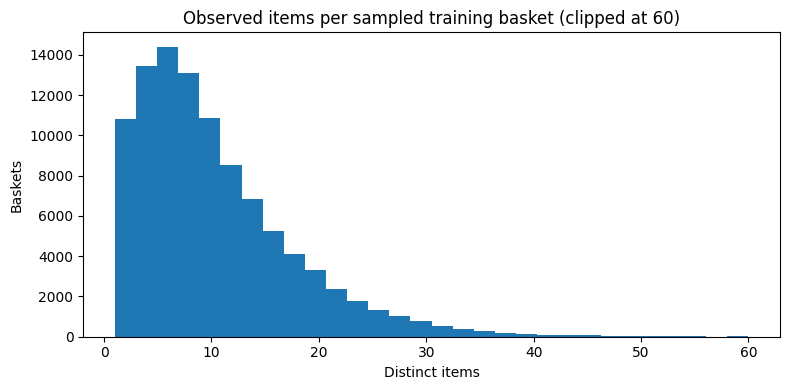

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

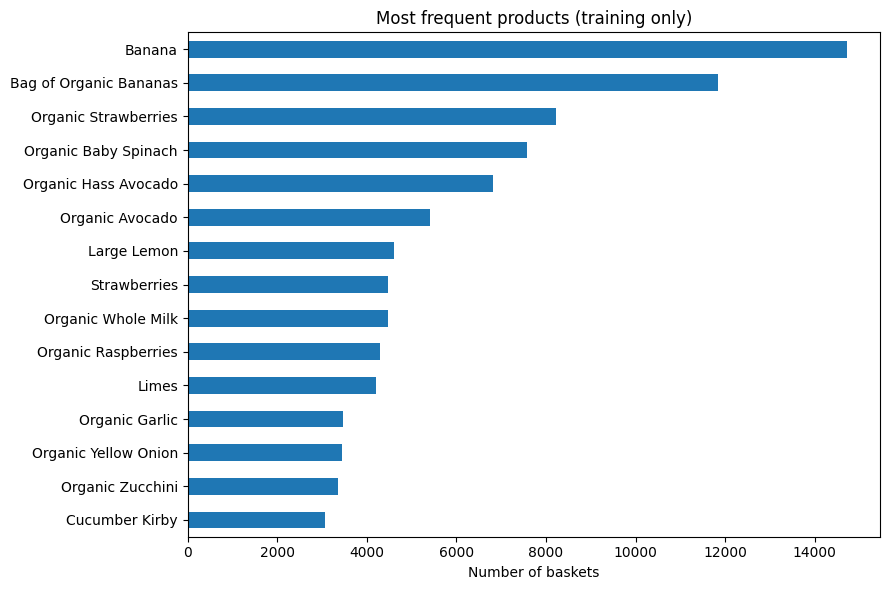

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [7]:
sizes=train_lines.groupby('order_id').product_id.nunique()
fig,ax=plt.subplots(figsize=(8,4));ax.hist(sizes.clip(upper=60),bins=30);ax.set(title='Observed items per sampled training basket (clipped at 60)',xlabel='Distinct items',ylabel='Baskets');fig.tight_layout();fig.savefig(OUT/'assets/plots/train_basket_sizes.png',dpi=155);plt.show()
fig,ax=plt.subplots(figsize=(9,6));pd.Series({item_labels[i]:int(counts[i]) for i in top_ids[:15]}).sort_values().plot.barh(ax=ax);ax.set(title='Most frequent products (training only)',xlabel='Number of baskets');fig.tight_layout();fig.savefig(OUT/'assets/plots/top_products.png',dpi=155);plt.show()

## 6. FP-Growth and Apriori benchmark
Run both on the same bounded Boolean matrix. If Apriori becomes too costly, notebook records an explicit skip, never implies execution. Use support/confidence/lift with a required absolute observation count.

In [8]:
result=[];itemsets={}
for algorithm,enabled,fn in [('fpgrowth',True,fpgrowth),('apriori',RUN_APRIORI,apriori)]:
    if not enabled:result.append({'algorithm':algorithm,'status':'disabled'});continue
    started=time.perf_counter()
    try:
        frequent=fn(train_b,min_support=MIN_SUPPORT,use_colnames=True,max_len=3)
        frequent['itemset_size']=frequent.itemsets.map(len)
        itemsets[algorithm]=frequent
        result.append({'algorithm':algorithm,'status':'ok','seconds':round(time.perf_counter()-started,2),'frequent_itemsets':len(frequent)})
        print(algorithm,len(frequent),'itemsets')
    except Exception as exc:
        result.append({'algorithm':algorithm,'status':'failed','error':str(exc)[:400]});print(algorithm,'FAILED',exc)
bench=pd.DataFrame(result);display(bench);bench.to_csv(OUT/'reports/algorithm_benchmark.csv',index=False)
assert 'fpgrowth' in itemsets,'FP-Growth unavailable; reduce TOP_PRODUCTS or MIN_SUPPORT' 

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

fpgrowth 92 itemsets


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

apriori 92 itemsets


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,algorithm,status,seconds,frequent_itemsets
0,fpgrowth,ok,3.67,92
1,apriori,ok,2.65,92


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

## 7. Rules and support safeguards
Export only single-item antecedents and consequents for understandable two-product bundles. Three-product baskets can be explored later. The rank is descriptive; high lift with tiny count is filtered.

In [9]:
freq=itemsets['fpgrowth']
if not freq.empty and (freq.itemsets.map(len)>=2).any():
    try:all_rules=association_rules(freq,metric='confidence',min_threshold=MIN_CONFIDENCE,num_itemsets=len(train_b))
    except TypeError:all_rules=association_rules(freq,metric='confidence',min_threshold=MIN_CONFIDENCE)
else:all_rules=pd.DataFrame()
if len(all_rules):
    rules=all_rules[(all_rules.antecedents.map(len)==1)&(all_rules.consequents.map(len)==1)&(all_rules.lift>=MIN_LIFT)].copy()
    rules['cooccurrence_train_baskets']=(rules.support*len(train_b)).round().astype(int)
    rules=rules[rules.cooccurrence_train_baskets>=max(25,int(len(train_b)*MIN_SUPPORT))]
    rules['antecedent_id']=rules.antecedents.map(lambda x:int(next(iter(x)).removeprefix('p_')))
    rules['consequent_id']=rules.consequents.map(lambda x:int(next(iter(x)).removeprefix('p_')))
    rules['antecedent_name']=rules.antecedent_id.map(item_labels)
    rules['consequent_name']=rules.consequent_id.map(item_labels)
    rules=rules.sort_values(['lift','confidence','support'],ascending=False).head(MAX_RULES_EXPORT).reset_index(drop=True)
else:rules=pd.DataFrame(columns=['antecedent_id','consequent_id','antecedent_name','consequent_name','support','confidence','lift','cooccurrence_train_baskets'])
print('Candidate rules:',len(rules));display(rules[['antecedent_name','consequent_name','support','confidence','lift','cooccurrence_train_baskets']].head(15))
assert len(rules)>0,'No usable rules with current threshold; inspect supports and consciously adjust params then rerun all.'
export_cols=['antecedent_id','consequent_id','antecedent_name','consequent_name','support','confidence','lift','cooccurrence_train_baskets']
rules[export_cols].to_csv(OUT/'models/instacart_rules.csv',index=False)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Candidate rules: 13


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,antecedent_name,consequent_name,support,confidence,lift,cooccurrence_train_baskets
0,Organic Hass Avocado,Bag of Organic Bananas,0.02030,0.297829,2.514383,2030
1,Bag of Organic Bananas,Organic Hass Avocado,0.02030,0.171380,2.514383,2030
2,Organic Raspberries,Bag of Organic Bananas,0.01271,0.296685,2.504731,1271
3,Organic Hass Avocado,Organic Strawberries,0.01276,0.187207,2.275791,1276
4,Organic Strawberries,Organic Hass Avocado,0.01276,0.155118,2.275791,1276
5,Organic Avocado,Banana,0.01640,0.302806,2.056970,1640
6,Bag of Organic Bananas,Organic Strawberries,0.01948,0.164458,1.999241,1948
7,Organic Strawberries,Bag of Organic Bananas,0.01948,0.236810,1.999241,1948
8,Strawberries,Banana,0.01295,0.289709,1.967999,1295
9,Large Lemon,Banana,0.01246,0.270693,1.838822,1246


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

## 8. Later-order rule evaluation
On held-out later orders, measure antecedent exposure, P(consequent | antecedent), global consequent prevalence and lift-like ratio. This is observational out-of-sample co-occurrence, **not** causal uplift or evidence of incremental sales.

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,antecedent_id,consequent_id,antecedent_name,consequent_name,train_confidence,train_lift,holdout_baskets,holdout_antecedent_baskets,holdout_joint_baskets,holdout_consequent_prevalence,holdout_confidence,holdout_lift_vs_global
0,47209,13176,Organic Hass Avocado,Bag of Organic Bananas,0.297829,2.514383,25000,1476,479,0.11528,0.324526,2.815109
1,13176,47209,Bag of Organic Bananas,Organic Hass Avocado,0.171380,2.514383,25000,2882,479,0.05904,0.166204,2.815109
2,27966,13176,Organic Raspberries,Bag of Organic Bananas,0.296685,2.504731,25000,1052,323,0.11528,0.307034,2.663378
3,47209,21137,Organic Hass Avocado,Organic Strawberries,0.187207,2.275791,25000,1476,314,0.07572,0.212737,2.809524
4,21137,47209,Organic Strawberries,Organic Hass Avocado,0.155118,2.275791,25000,1893,314,0.05904,0.165874,2.809524
5,47766,24852,Organic Avocado,Banana,0.302806,2.056970,25000,1335,394,0.14488,0.295131,2.037073
6,13176,21137,Bag of Organic Bananas,Organic Strawberries,0.164458,1.999241,25000,2882,528,0.07572,0.183206,2.419521
7,21137,13176,Organic Strawberries,Bag of Organic Bananas,0.236810,1.999241,25000,1893,528,0.11528,0.278922,2.419521
8,16797,24852,Strawberries,Banana,0.289709,1.967999,25000,1218,357,0.14488,0.293103,2.023077
9,47626,24852,Large Lemon,Banana,0.270693,1.838822,25000,1425,374,0.14488,0.262456,1.811542


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

{
  "holdout_baskets": 25000,
  "rules_train": 13,
  "rules_with_30_or_more_antecedent_baskets": 13,
  "holdout_vocabulary_item_coverage": 0.24126905860690154,
  "median_holdout_confidence_supported": 0.22890946502057613,
  "median_holdout_lift_supported": 2.4195206929507265,
  "evaluation_note": "Out-of-sample basket co-occurrence; not personalized CTR, causal lift or bundle revenue."
}


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

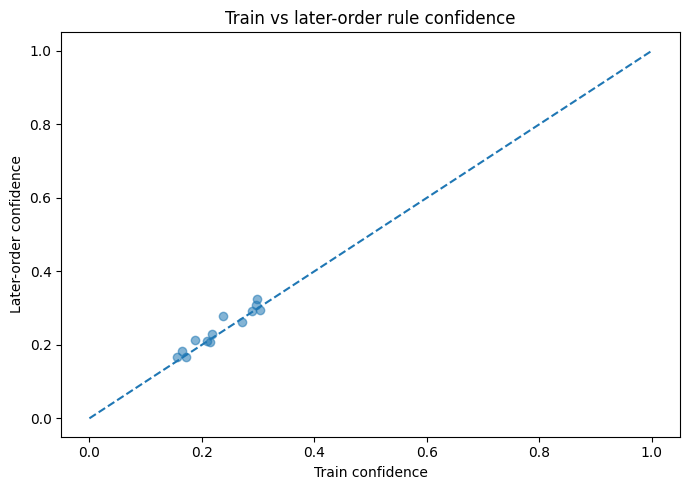

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [10]:
matrix=test_b.to_numpy(dtype=bool);col_idx={int(i):j for j,i in enumerate(top_ids)}
records=[]
for row in rules.itertuples():
    a=matrix[:,col_idx[row.antecedent_id]];b=matrix[:,col_idx[row.consequent_id]]
    n_a=int(a.sum());n_b=int(b.sum());both=int((a&b).sum());n=len(test_b)
    conf=both/n_a if n_a else float('nan');base=n_b/n if n else float('nan')
    records.append({'antecedent_id':row.antecedent_id,'consequent_id':row.consequent_id,'antecedent_name':row.antecedent_name,'consequent_name':row.consequent_name,'train_confidence':row.confidence,'train_lift':row.lift,'holdout_baskets':n,'holdout_antecedent_baskets':n_a,'holdout_joint_baskets':both,'holdout_consequent_prevalence':base,'holdout_confidence':conf,'holdout_lift_vs_global':(conf/base if n_a and base else float('nan'))})
held=pd.DataFrame(records)
held.to_csv(OUT/'reports/instacart_heldout_rule_evaluation.csv',index=False)
display(held.head(15))
supported=held[held.holdout_antecedent_baskets>=30].copy()
metrics={'holdout_baskets':int(len(test_b)),'rules_train':int(len(rules)),'rules_with_30_or_more_antecedent_baskets':int(len(supported)),'holdout_vocabulary_item_coverage':coverage,'median_holdout_confidence_supported':float(supported.holdout_confidence.median()) if len(supported) else None,'median_holdout_lift_supported':float(supported.holdout_lift_vs_global.median()) if len(supported) else None,'evaluation_note':'Out-of-sample basket co-occurrence; not personalized CTR, causal lift or bundle revenue.'}
(OUT/'reports/instacart_heldout_metrics.json').write_text(json.dumps(metrics,indent=2),encoding='utf-8')
print(json.dumps(metrics,indent=2))
fig,ax=plt.subplots(figsize=(7,5));ax.scatter(held.train_confidence,held.holdout_confidence,alpha=.55);ax.plot([0,1],[0,1],linestyle='--');ax.set(xlabel='Train confidence',ylabel='Later-order confidence',title='Train vs later-order rule confidence');fig.tight_layout();fig.savefig(OUT/'assets/plots/train_vs_holdout_confidence.png',dpi=155);plt.show()

## 9. UCI Online Retail II — independent retail domain
Parse workbook without combining product IDs with Instacart. Remove cancelled invoices, nonpositive quantities, invalid stock codes, blank invoices. If memory becomes constrained, evaluate a bounded number of invoices, disclosed in reports. Temporal split by `InvoiceDate` per source only.

In [11]:
kind,path,member=uci_candidates[0]
if kind=='zip':
    with zipfile.ZipFile(path) as z:
        with z.open(member) as h:uci=pd.read_excel(BytesIO(h.read()),sheet_name=None)
else:uci=pd.read_excel(path,sheet_name=None)
print('UCI sheets:',{k:len(v) for k,v in uci.items()})
frames=[]
for year,df in uci.items():
    d=df.copy();d.columns=[str(x).strip().lower().replace(' ','') for x in d.columns]
    invoices=next((x for x in ('invoice','invoiceno') if x in d.columns),None)
    needed=('stockcode','quantity','invoicedate')
    assert invoices and all(x in d for x in needed),f'Unexpected UCI columns in {year}: {d.columns.tolist()}'
    temp=d[[invoices,'stockcode','quantity','invoicedate']].rename(columns={invoices:'invoice'})
    temp['sheet']=str(year)
    frames.append(temp)
uci=pd.concat(frames,ignore_index=True)
n_input=len(uci)
uci['invoice']=uci.invoice.astype('string').str.strip();uci['stockcode']=uci.stockcode.astype('string').str.strip()
uci['quantity']=pd.to_numeric(uci.quantity,errors='coerce');uci['invoicedate']=pd.to_datetime(uci.invoicedate,errors='coerce')
uci=uci.dropna(subset=['invoice','stockcode','quantity','invoicedate'])
uci=uci[(uci.quantity>0)&(~uci.invoice.str.upper().str.startswith('C',na=False))&(uci.stockcode.str.len()>0)].copy()
# Shop-level invoice key; prevent accidental overlap across workbook sheets
uci['basket_id']=uci['sheet']+'::'+uci['invoice']
uci=uci[['basket_id','stockcode','invoicedate']].drop_duplicates(['basket_id','stockcode'])
invoice_time=uci.groupby('basket_id').invoicedate.min().sort_values()
cut=int(len(invoice_time)*.8)
assert cut>0 and cut<len(invoice_time)
uci_train_orders=invoice_time.index[:cut].tolist()
uci_test_orders=invoice_time.index[cut:].tolist()
print('UCI raw',n_input,'filtered product lines',len(uci),'train invoices',len(uci_train_orders),'later invoices',len(uci_test_orders))
(OUT/'reports/uci_cleaning.json').write_text(json.dumps({'raw_rows':n_input,'filtered_unique_invoice_items':len(uci),'train_invoices':len(uci_train_orders),'later_invoices':len(uci_test_orders),'selection':'80% earliest invoices by InvoiceDate; latest 20% held out','caution':'No storewide business performance inferred'},indent=2),encoding='utf-8')

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

UCI sheets: {'Year 2009-2010': 525461, 'Year 2010-2011': 541910}


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

UCI raw 1067371 filtered product lines 1020658 train invoices 34264 later invoices 8567


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


257

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 10. UCI rule mining and later-period diagnostic

In [12]:
u_train=uci[uci.basket_id.isin(uci_train_orders)]
u_test=uci[uci.basket_id.isin(uci_test_orders)]
u_top=u_train.stockcode.value_counts().head(min(100,TOP_PRODUCTS)).index.tolist()
# Limit input rows deterministically while preserving chronological ordering; record subset policy
u_train_ids=uci_train_orders[-min(75_000,len(uci_train_orders)):]
u_test_ids=uci_test_orders[:min(25_000,len(uci_test_orders))]

def make_uci_basket(df,ids,items):
    m={v:i for i,v in enumerate(ids)};c={v:i for i,v in enumerate(items)}
    d=df[df.basket_id.isin(m)&df.stockcode.isin(c)]
    arr=csr_matrix((np.ones(len(d),dtype=np.uint8),(d.basket_id.map(m),d.stockcode.map(c))),shape=(len(ids),len(items)))
    return pd.DataFrame(arr.toarray()>0,columns=['sku_'+str(x) for x in items])
ub_train=make_uci_basket(u_train,u_train_ids,u_top);ub_test=make_uci_basket(u_test,u_test_ids,u_top)
print('UCI matrices',ub_train.shape,ub_test.shape)
u_freq=fpgrowth(ub_train,min_support=0.018,use_colnames=True,max_len=2)
if len(u_freq) and any(u_freq.itemsets.map(len)>=2):
    try:u_rules=association_rules(u_freq,metric='confidence',min_threshold=0.12,num_itemsets=len(ub_train))
    except TypeError:u_rules=association_rules(u_freq,metric='confidence',min_threshold=0.12)
    u_rules=u_rules[(u_rules.antecedents.map(len)==1)&(u_rules.consequents.map(len)==1)].copy()
    u_rules['antecedent_sku']=u_rules.antecedents.map(lambda v:next(iter(v)).removeprefix('sku_'))
    u_rules['consequent_sku']=u_rules.consequents.map(lambda v:next(iter(v)).removeprefix('sku_'))
    u_rules=u_rules.sort_values('lift',ascending=False).head(250)
else:u_rules=pd.DataFrame(columns=['antecedent_sku','consequent_sku','support','confidence','lift'])
u_rules[['antecedent_sku','consequent_sku','support','confidence','lift']].to_csv(OUT/'models/uci_rules.csv',index=False)
ui={str(i):j for j,i in enumerate(u_top)};un=ub_test.to_numpy(dtype=bool)
u_eval=[]
for row in u_rules.itertuples():
    a=un[:,ui[row.antecedent_sku]];b=un[:,ui[row.consequent_sku]];na=int(a.sum())
    u_eval.append({'antecedent_sku':row.antecedent_sku,'consequent_sku':row.consequent_sku,'test_antecedent_count':na,'test_conditional_rate':float((a&b).sum()/na) if na else None,'train_confidence':float(row.confidence)})
pd.DataFrame(u_eval,columns=['antecedent_sku','consequent_sku','test_antecedent_count','test_conditional_rate','train_confidence']).to_csv(OUT/'reports/uci_later_period_rule_evaluation.csv',index=False)
print('UCI rules mined:',len(u_rules));display(u_rules[['antecedent_sku','consequent_sku','support','confidence','lift']].head(10))
(OUT/'reports/uci_metrics.json').write_text(json.dumps({'n_train_baskets':len(ub_train),'n_test_baskets':len(ub_test),'n_rules':len(u_rules),'n_skus':len(u_top),'warning':'Independent UCI product space; no cross-dataset ID join or comparable pooled lift'},indent=2),encoding='utf-8')

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

UCI matrices (34264, 100) (8567, 100)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

UCI rules mined: 150


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,antecedent_sku,consequent_sku,support,confidence,lift
149,22699,22697,0.023465,0.734918,23.778301
148,22697,22699,0.023465,0.759207,23.778301
147,22630,22629,0.018503,0.610790,19.724890
146,22629,22630,0.018503,0.597549,19.724890
47,20724,22356,0.025566,0.534146,13.865144
46,22356,20724,0.025566,0.663636,13.865144
107,20724,20723,0.021042,0.439634,13.121624
106,20723,20724,0.021042,0.628049,13.121624
71,20719,22355,0.019700,0.522042,12.378712
70,22355,20719,0.019700,0.467128,12.378712


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


189

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 11. Bundle suggestions, app-ready feature contracts
Keep fields interpretable and permit users to reject the suggestion. Product pairing is not a discount recommendation.

In [13]:
suggestions=rules[export_cols].copy()
suggestions['suggested_action']='Review merchandising bundle candidate; human decides'
suggestions['caution']='Historical association only; no causality or incremental revenue'
suggestions.to_csv(OUT/'exports/instacart_bundle_suggestions.csv',index=False)
# App input is the list of eligible SKUs and corresponding names, not incomplete lag features
pd.DataFrame([{'product_id':k,'product_name':v} for k,v in item_labels.items()]).to_csv(OUT/'exports/product_catalog.csv',index=False)
(OUT/'models/model_config.json').write_text(json.dumps({'project':'BundleRecommender','version':'day20-full-master-v1','model_type':'association_rules_not_fitted_estimator','primary_rules_file':'instacart_rules.csv','secondary_rules_file':'uci_rules.csv','input_schema':{'product_id':'integer Instacart product ID present in product_catalog.csv'},'output_schema':{'consequent_id':'integer','confidence':'historical train co-occurrence conditional rate','lift':'historical train lift','support':'historical train basket support'},'parameters':{'top_products':TOP_PRODUCTS,'min_support':MIN_SUPPORT,'min_confidence':MIN_CONFIDENCE,'min_lift':MIN_LIFT},'limitations':['Not a per-user recommender','Not causal revenue gain','Different SKU vocabularies in UCI and Instacart','Requires manual merchandising approval']},indent=2),encoding='utf-8')
print('App-ready suggestion CSV rows:',len(suggestions))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

App-ready suggestion CSV rows: 13


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

## 12. Visual comparison and final summary

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

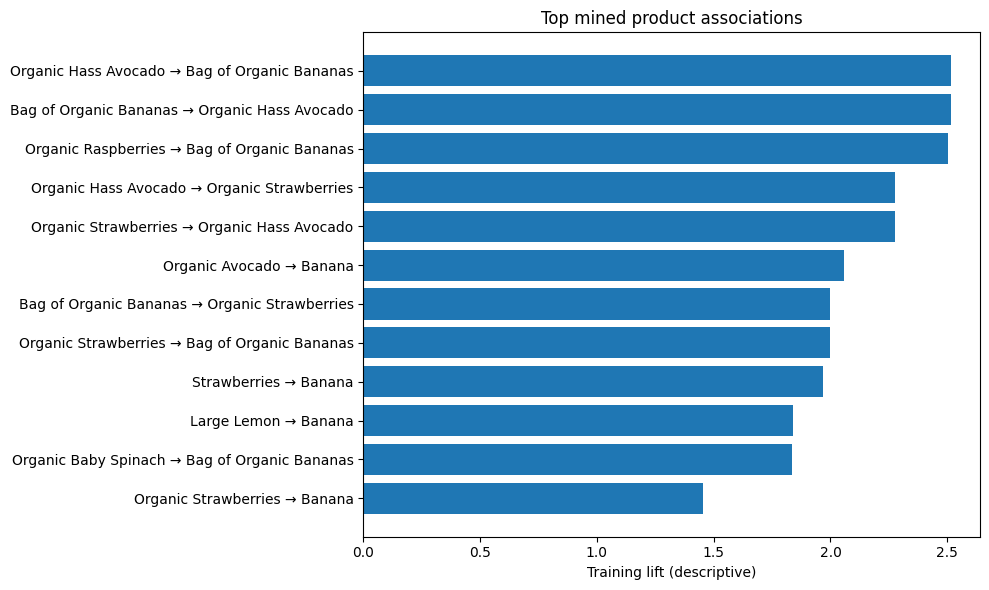

{
  "project": "Day 20 BundleRecommender",
  "status": "research prototype",
  "sources": [
    "Instacart Market Basket Analysis",
    "UCI Online Retail II"
  ],
  "basket_selection": "Per user earlier prior orders for training, latest prior for holdout; sampled train subset",
  "instacart": {
    "holdout_baskets": 25000,
    "rules_train": 13,
    "rules_with_30_or_more_antecedent_baskets": 13,
    "holdout_vocabulary_item_coverage": 0.24126905860690154,
    "median_holdout_confidence_supported": 0.22890946502057613,
    "median_holdout_lift_supported": 2.4195206929507265,
    "evaluation_note": "Out-of-sample basket co-occurrence; not personalized CTR, causal lift or bundle revenue."
  },
  "uci": {
    "n_train_baskets": 34264,
    "n_test_baskets": 8567,
    "n_rules": 150,
    "n_skus": 100,
    "warning": "Independent UCI product space; no cross-dataset ID join or comparable pooled lift"
  },
  "algorithm_benchmark": [
    {
      "algorithm": "fpgrowth",
      "status": "ok",

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [14]:
if len(rules):
    top=rules.head(12).iloc[::-1]
    fig,ax=plt.subplots(figsize=(10,6))
    labels=[f'{str(a)[:23]} → {str(b)[:23]}' for a,b in zip(top.antecedent_name,top.consequent_name)]
    ax.barh(labels,top.lift);ax.set(xlabel='Training lift (descriptive)',title='Top mined product associations')
    fig.tight_layout();fig.savefig(OUT/'assets/plots/top_bundle_lift.png',dpi=155);plt.show()
summary={'project':'Day 20 BundleRecommender','status':'research prototype','sources':['Instacart Market Basket Analysis','UCI Online Retail II'],'basket_selection':'Per user earlier prior orders for training, latest prior for holdout; sampled train subset','instacart':metrics,'uci':json.loads((OUT/'reports/uci_metrics.json').read_text()),'algorithm_benchmark':result,'no_causal_claim':True,'limits':['Trained on bounded top product catalog','No causal basket lift','Period-shift and cold-start possible','No revenue conversion metrics','Rules used for product suggestions with human approval']}
(OUT/'reports/final_summary.json').write_text(json.dumps(summary,indent=2,ensure_ascii=False),encoding='utf-8')
print(json.dumps(summary,indent=2,ensure_ascii=False))

## 13. Lightweight inference parity test (from exported rules)

In [15]:
saved=pd.read_csv(OUT/'models/instacart_rules.csv')
assert len(saved)==len(rules)
assert saved[['antecedent_id','consequent_id']].equals(rules[['antecedent_id','consequent_id']].reset_index(drop=True))
example=int(saved.iloc[0].antecedent_id)
recs=saved[saved.antecedent_id.eq(example)].sort_values('lift',ascending=False).head(5)
print('Input product:',item_labels[example]);display(recs[['consequent_name','confidence','lift','support']])
assert recs.consequent_id.ne(example).all()
print('Rule serialization/inference lookup parity: PASS')

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Input product: Organic Hass Avocado


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,consequent_name,confidence,lift,support
0,Bag of Organic Bananas,0.297829,2.514383,0.02030
3,Organic Strawberries,0.187207,2.275791,0.01276


Rule serialization/inference lookup parity: PASS


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

## 14. Release archive + source manifest
ZIP includes only model rule tables, reports, aggregated plots, app-ready exports and docs; excludes original Instacart/UCI data. Review data licensing independently.

In [16]:
README = """# BundleRecommender — Day 20/100 Research Artifacts

Basket co-occurrence mining from Instacart plus independent UCI Online Retail II. FP-Growth and Apriori benchmarked with bounded SKU catalog. Instacart has per-user later-order holdout; UCI uses invoice-date holdout.

- `models/instacart_rules.csv`: top train associations (observed, no fabricated scores)
- `models/uci_rules.csv`: separate domain; do not join to Instacart
- `models/model_config.json`: inference contract, semantics and thresholds
- `reports/final_summary.json`: observed results and protocols
- `reports/`: structured audits, runtime and holdout evaluation
- `assets/plots/`: images generated from the analyzed data
- `exports/`: app-ready rules and products, not raw transaction histories

Limitations: Association is not causation. Lift is not incremental revenue. No A/B test, forecast or production KPI is asserted. Raw third-party datasets are not redistributed.

Sources: Instacart https://www.kaggle.com/competitions/instacart-market-basket-analysis/data ; UCI https://archive.ics.uci.edu/dataset/502/online+retail+ii (CC BY 4.0). Mirror can have separate usage conditions.
"""
(OUT/'README.md').write_text(README,encoding='utf-8')
release=[p for d in ['models','reports','assets/plots','exports'] for p in (OUT/d).rglob('*') if p.is_file()]
release += [OUT/'README.md']
checks={str(p.relative_to(OUT)):hashlib.sha256(p.read_bytes()).hexdigest() for p in release}
(OUT/'reports/release_sha256.json').write_text(json.dumps(checks,indent=2),encoding='utf-8')
release += [OUT/'reports/release_sha256.json']
archive=Path('/kaggle/working/BundleRecommender_Day20_FULL_MASTER_v1_RELEASE.zip')
with zipfile.ZipFile(archive,'w',compression=zipfile.ZIP_DEFLATED) as z:
    for p in release:z.write(p,arcname=p.relative_to(OUT))
with zipfile.ZipFile(archive) as z:assert z.testzip() is None
print('ZIP:',archive,'MB:',round(archive.stat().st_size/2**20,2))
for p in release:print(' -',p.relative_to(OUT))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

ZIP: /kaggle/working/BundleRecommender_Day20_FULL_MASTER_v1_RELEASE.zip MB: 0.24
 - models/instacart_rules.csv
 - models/model_config.json
 - models/uci_rules.csv
 - reports/uci_later_period_rule_evaluation.csv
 - reports/instacart_heldout_metrics.json
 - reports/source_contract.json
 - reports/uci_cleaning.json
 - reports/final_summary.json
 - reports/uci_metrics.json
 - reports/input_inventory.csv
 - reports/instacart_heldout_rule_evaluation.csv
 - reports/algorithm_benchmark.csv
 - reports/instacart_integrity.json
 - reports/split_stats.csv
 - reports/top_products_training.csv
 - assets/plots/train_basket_sizes.png
 - assets/plots/train_vs_holdout_confidence.png
 - assets/plots/top_products.png
 - assets/plots/top_bundle_lift.png
 - exports/instacart_bundle_suggestions.csv
 - exports/product_catalog.csv
 - README.md
 - reports/release_sha256.json


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

## Interpretation / next

1. Run all cells, then inspect `reports/final_summary.json` and `reports/instacart_heldout_rule_evaluation.csv` before making claims.
2. A small/high training lift can regress out of sample; only promote rules with adequate later-order exposure.
3. The secondary UCI experiment is **not pooled** with Instacart.
4. Build the Streamlit product selector from `models/model_config.json`, `exports/product_catalog.csv`, and `models/instacart_rules.csv`.
5. If data audit errors appear, report exact input paths/headers, never silently rename IDs or synthesize transactions.
6. Commit message after checking results: `feat(ml): add Day 20 basket association research and heldout rules`.
